## Cargar la señal

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

path = "https://raw.githubusercontent.com/AndreaRazuriMadrid/intro-senales-biomedicas/main/ISB/Lab%204-%20ECG/se%C3%B1ales/Ejercicio.txt"
data = np.genfromtxt(path, delimiter="\t", skip_header=3)
data, data.shape

(array([[ 0.,  0.,  0., ..., 26.,  1., nan],
        [ 1.,  0.,  0., ..., 26.,  1., nan],
        [ 2.,  0.,  0., ..., 26.,  1., nan],
        ...,
        [ 3.,  0.,  0., ..., 26.,  1., nan],
        [ 4.,  0.,  0., ..., 26.,  1., nan],
        [ 5.,  0.,  0., ..., 26.,  1., nan]]),
 (14550, 12))

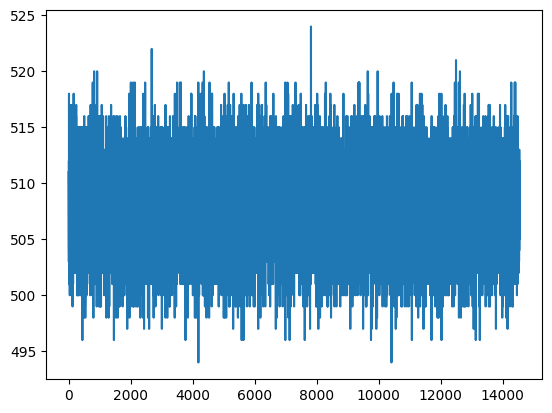

In [ ]:
# En la columna 5 esta la señal
plt.plot(data[:,5])

## Configurar el EDGE IMPULSE

https://www.edgeimpulse.com/blog/announcing-new-python-sdk-features-upload-and-download-samples/

In [ ]:
!pip install edgeimpulse

In [ ]:
import edgeimpulse as ei
import pandas as pd

ei.API_KEY = "ei_a9eeaf3cb57e88204c116369134a479440eac9f9713cedce"

In [ ]:
df_1 = pd.DataFrame(data[:,5], columns=["signal"])

# Upload the first sample
ids = []
response = ei.experimental.data.upload_pandas_sample(
    df_1,
    label="EMG",
    filename="001",
    sample_rate_ms=1,
    category="training",
)

In [ ]:
assert len(response.fails) == 0, "Could not upload some files"
for sample in response.successes:
    ids.append(sample.sample_id)

In [ ]:
ids

[2955464913]

In [ ]:
# Subir en grupo
"""
for i in range(len(l_aux_df)):
    ids = []
    response = ei.experimental.data.upload_pandas_sample(
        l_aux_df[i][["signal"]],
        label="prueba",
        filename="00"+str(i),
        sample_rate_ms=1,
        category="training",
    )

    assert len(response.fails) == 0, "Could not upload some files"
    for sample in response.successes:
        ids.append(sample.sample_id)
"""

'\nfor i in range(len(l_aux_df)):\n    ids = []\n    response = ei.experimental.data.upload_pandas_sample(\n        l_aux_df[i][["signal"]],\n        label="prueba",\n        filename="00"+str(i),\n        sample_rate_ms=1,\n        category="training",\n    )\n\n    assert len(response.fails) == 0, "Could not upload some files"\n    for sample in response.successes:\n        ids.append(sample.sample_id)\n'

# Envio de señales EKG de neurokit2

In [ ]:
import sys
!{sys.executable} -m pip install neurokit2

In [ ]:
import neurokit2 as nk
import numpy as np
import pandas as pd
import edgeimpulse as ei

# Define parameters
sampling_rate = 1000  # 1 kHz
duration = 10         # 10 seconds
num_signals_per_group = 10
bpms = [50, 70, 120]

# Store uploaded sample IDs
all_uploaded_ids = []

print(f"Generating and uploading {len(bpms) * num_signals_per_group} ECG signals...")

for bpm in bpms:
    print(f"\nGenerating {num_signals_per_group} signals for {bpm} BPM...")
    for i in range(num_signals_per_group):
        # Generate ECG signal
        ecg_signal = nk.ecg_simulate(duration=duration, sampling_rate=sampling_rate, heart_rate=bpm)

        # Create DataFrame for upload
        # The `upload_pandas_sample` expects a single 'signal' column
        df_signal = pd.DataFrame(ecg_signal, columns=["signal"])

        # Define filename and label
        filename = f"ecg_{bpm}bpm_{i+1:03d}"
        label = f"ECG_{bpm}bpm"

        # Upload to Edge Impulse
        response = ei.experimental.data.upload_pandas_sample(
            df_signal,
            label=label,
            filename=filename,
            sample_rate_ms=1, # 1 sample per millisecond = 1kHz
            category="training" # All generated as training data
        )

        if len(response.fails) > 0:
            print(f"Failed to upload {filename} for {label}: {response.fails}")
        else:
            for sample in response.successes:
                all_uploaded_ids.append(sample.sample_id)
                # print(f"Successfully uploaded: {filename} (ID: {sample.sample_id})")

print(f"\nFinished uploading all signals. Total uploaded: {len(all_uploaded_ids)}")
print("All uploaded sample IDs:")
print(all_uploaded_ids)

Generating and uploading 30 ECG signals...

Generating 10 signals for 50 BPM...

Generating 10 signals for 70 BPM...

Generating 10 signals for 120 BPM...

Finished uploading all signals. Total uploaded: 30
All uploaded sample IDs:
[2955554486, 2955554488, 2955554489, 2955554493, 2955554495, 2955554496, 2955554498, 2955554500, 2955554502, 2955554507, 2955554512, 2955554516, 2955554518, 2955554519, 2955554521, 2955554524, 2955554525, 2955554526, 2955554528, 2955554529, 2955554531, 2955554534, 2955554535, 2955554538, 2955554551, 2955554710, 2955554839, 2955555053, 2955555286, 2955555509]
